# P2b · Effet du REV Saint-Denis sur la piste Brébeuf : différence de différences

Le Réseau express vélo (REV) de la rue Saint-Denis ouvre en novembre 2020. La piste Brébeuf, parallèle et à quelques rues, a-t-elle perdu des cyclistes ? Brébeuf est comparée avant et après le REV, par rapport à des compteurs témoins.

Données : Ville de Montréal, compteurs cyclistes permanents, 2015 à 2023, licence CC BY 4.0. Les fichiers se placent dans `donnees/` (voir le README).

## Hypothèse et plan (rédigés avant d'ouvrir les comptages)

**Hypothèse.** Le REV Saint-Denis, inauguré le 7 novembre 2020, redirige des cyclistes : le passage diminue sensiblement sur les pistes parallèles proches, comme Brébeuf, mais pas sur les axes perpendiculaires.

**Piste traitée.** Brébeuf, parallèle au REV, à quelques rues.

**Témoins.** Des pistes que le REV ne touche pas : est-ouest, ou parallèles mais loin. Pas une piste parallèle collée au REV, qui serait touchée elle aussi.

**Années comparées.** Avant : 2018-2019. Après : 2021-2022.

**Facteur de confusion : 2020.** La COVID (confinement, télétravail, pistes temporaires) change tous les trajets la même année que l'ouverture du REV : 2020 est exclue.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Charte commune des figures du dépôt (style/charte.py) : polices, couleurs, export clair et sombre
sys.path.insert(0, "../../style")
from charte import charger_charte, en_francais, pourcentage, sauver_clair_et_sombre
charger_charte()
Path("resultats").mkdir(exist_ok=True)

## 1. Deux formats de comptage

De 2015 à 2018 : une ligne par jour, une colonne par compteur désigné par son nom. Depuis 2019 : une ligne par quart d'heure et par compteur, désigné par un numéro. Les deux sont ramenés à une ligne par jour et par compteur ; `sites.csv` relie les noms aux numéros.

In [2]:
compteurs_2018 = pd.read_csv("donnees/comptage_2018.csv")
compteurs_2022 = pd.read_csv("donnees/comptage_2022.csv")

display(compteurs_2018.head(3))
display(compteurs_2022.head(3))
print("2018 :", compteurs_2018.shape, "  2022 :", compteurs_2022.shape)

,Date,Unnamed: 1,Berri1,Boyer,Boyer 2,Brébeuf,Christophe-Colomb,CSC (Côte Sainte-Catherine),Eco-Display Parc Stanley,Eco-Totem - Métro Laurier,...,Parc,PierDup,Pont Jacques-Cartier,Rachel / Hôtel de Ville,Rachel / Papineau,René-Lévesque,Saint-Antoine,Saint-Laurent/Bellechasse,Saint-Urbain,Viger
0,01/01/2018,00:00,29,30,18.0,2,8.0,7,NaN,52,...,15,0,8.0,40,62,7,3,58,13,NaN
1,02/01/2018,00:00,94,71,32.0,0,6.0,23,NaN,78,...,38,0,5.0,92,144,35,3,143,23,NaN
2,03/01/2018,00:00,200,149,54.0,0,30.0,58,NaN,112,...,76,4,9.0,160,273,62,37,314,21,NaN


,date,heure,id_compteur,longitude,latitude,nb_passages
0,2022-01-01,00:00:00,100054073,-73.590636,45.560713,0
1,2022-01-01,00:00:00,300021685,-73.613370,45.631590,0
2,2022-01-01,00:00:00,100003040,-73.544410,45.501270,0


2018 : (365, 25)   2022 : (1870506, 6)


In [3]:
sites = pd.read_csv("donnees/sites.csv", sep=";", encoding="utf-8-sig", dtype={"instance": str})
sites[sites["Nom Rue Global"].str.contains("Brébeuf")]

,instance,Source,Nom Rue Global,Latitude,Longitude
8,100004575,ECO-Compteur,Brébeuf / Rachel,45.527496,-73.57432


In [4]:
# Nom dans les fichiers 2015-2018 → numéro dans les fichiers 2019+ (d'après sites.csv)
numero_par_nom = {
    "Brébeuf": "100004575",
    "Parc": "100003042",                  # Parc / Duluth
    "Rachel / Papineau": "100003034",
    "Berri1": "100003032",                # Berri / BanQ (déduit de la continuité des totaux)
    "Rachel / Hôtel de Ville": "100012217",
}
nom_par_numero = {numero: nom for nom, numero in numero_par_nom.items()}


def lire_ancien(annee):
    """2015-2018 : une colonne par compteur → une ligne par jour et par compteur."""
    large = pd.read_csv(f"donnees/comptage_{annee}.csv")
    large["date"] = pd.to_datetime(large["Date"], dayfirst=True)     # dates en jour/mois/année
    return large.melt(id_vars="date", value_vars=list(numero_par_nom),
                      var_name="compteur", value_name="passages")


def lire_recent(annee):
    """2019 et après : quarts d'heure par numéro → somme par jour, puis le nom."""
    quart = pd.read_csv(f"donnees/comptage_{annee}.csv", dtype={"id_compteur": str})
    quart = quart[quart["id_compteur"].isin(nom_par_numero)]
    jour = quart.groupby(["date", "id_compteur"], as_index=False)["nb_passages"].sum()
    jour["date"] = pd.to_datetime(jour["date"])
    jour["compteur"] = jour["id_compteur"].map(nom_par_numero)
    return jour.rename(columns={"nb_passages": "passages"})[["date", "compteur", "passages"]]


jours = pd.concat(
    [lire_ancien(a) for a in range(2015, 2019)] + [lire_recent(a) for a in range(2019, 2024)],
    ignore_index=True,
)
print(jours.shape)
jours.head()

(16430, 3)


,date,compteur,passages
0,2015-01-01,Brébeuf,4.0
1,2015-01-02,Brébeuf,5.0
2,2015-01-03,Brébeuf,3.0
3,2015-01-04,Brébeuf,21.0
4,2015-01-05,Brébeuf,2.0


## 2. Couverture des compteurs

Un compteur en panne affiche zéro, ce qui ressemblerait à une piste vide : on compte d'abord les jours actifs (au moins un passage).

In [5]:
jours["annee"] = jours["date"].dt.year
jours_actifs = (
    jours[jours["passages"] > 0]          # un jour « actif » = au moins un passage
    .groupby(["annee", "compteur"])
    .size()
    .unstack()
)
jours_actifs

compteur,Berri1,Brébeuf,Parc,Rachel / Hôtel de Ville,Rachel / Papineau
annee,,,,,
2015,365,357,345,324,365
2016,366,365,366,180,310
2017,365,358,365,365,365
2018,362,355,365,365,365
2019,365,82,365,313,365
2020,366,268,361,366,365
2021,365,95,365,365,365
2022,365,272,365,190,365
2023,365,291,365,365,274


Le compteur de Brébeuf est presque muet en 2019 (82 jours actifs) et ne reprend qu'en fin d'année 2021 (95 jours). 2020 reste exclue : la pandémie y modifie tous les déplacements et le REV ouvre en novembre. Le plan initial (2018-2019 contre 2021-2022) devient : **avant = 2015-2018, après = 2022-2023**. Les trous de 2022 et 2023 sont traités en ne comparant que les jours où tous les compteurs comptent.

## 3. Choix des témoins

Un bon témoin est loin du REV et ne lui sert pas de route de rechange.

In [6]:
sites_rev = sites[sites["Nom Rue Global"].str.contains("REV St") & sites["Nom Rue Global"].str.contains("Denis")]


def distance_au_rev_km(latitude, longitude):
    """Distance à vol d'oiseau jusqu'au compteur du REV le plus proche (approximation plane, suffisante à l'échelle de Montréal)."""
    nord_sud = (sites_rev["Latitude"] - latitude) * 111.2
    est_ouest = (sites_rev["Longitude"] - longitude) * 111.2 * np.cos(np.radians(45.52))
    return np.sqrt(nord_sud**2 + est_ouest**2).min()


candidats = sites[sites["instance"].isin(nom_par_numero)].copy()
candidats["compteur"] = candidats["instance"].map(nom_par_numero)
candidats["km_du_REV"] = [distance_au_rev_km(la, lo) for la, lo in zip(candidats["Latitude"], candidats["Longitude"])]
candidats[["compteur", "Nom Rue Global", "km_du_REV"]].sort_values("km_du_REV").round(2)

,compteur,Nom Rue Global,km_du_REV
13,Rachel / Hôtel de Ville,Rachel / HôteldeVille,0.29
8,Brébeuf,Brébeuf / Rachel,0.71
7,Parc,Parc / Duluth,0.89
2,Berri1,Berri / BanQ,1.14
3,Rachel / Papineau,Rachel / Papineau,1.18


Rachel / Hôtel-de-Ville, à 0,29 km du REV, est écarté (il est aussi incomplet en 2016 et en 2022). Témoins retenus : Parc, Rachel / Papineau et Berri1, à environ 1 km.

## 4. Tendances parallèles

La différence de différences suppose que, sans le REV, Brébeuf aurait évolué comme les témoins. Mesure : la part de Brébeuf dans les passages des trois témoins, de mai à octobre, sur les jours où les quatre compteurs comptent.

date
2015    0.389
2016    0.380
2017    0.333
2018    0.311
2022    0.139
2023    0.113
dtype: float64

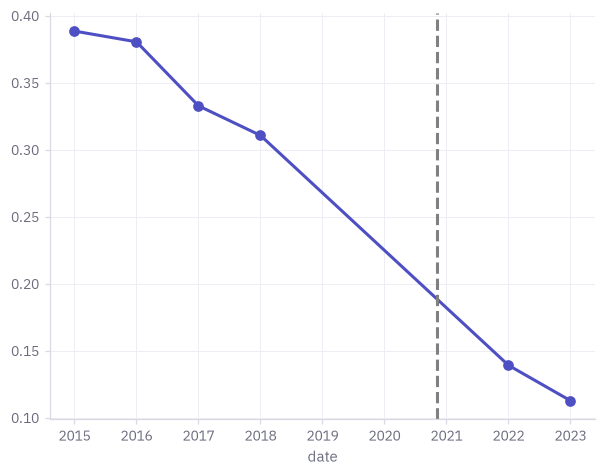

In [7]:
temoins = ["Parc", "Rachel / Papineau", "Berri1"]
annees_du_plan = [2015, 2016, 2017, 2018, 2022, 2023]

tableau = jours.pivot_table(index="date", columns="compteur", values="passages")   # une colonne par compteur
# mai à octobre : l'hiver, certaines pistes sont fermées ou mal déneigées
saison = tableau[tableau.index.month.isin([5, 6, 7, 8, 9, 10]) & tableau.index.year.isin(annees_du_plan)]
communs = saison[["Brébeuf"] + temoins]
communs = communs[(communs > 0).all(axis=1)]       # seulement les jours où les 4 compteurs ont compté

annee = communs.index.year
part_brebeuf = communs["Brébeuf"].groupby(annee).sum() / communs[temoins].sum(axis=1).groupby(annee).sum()

ax = part_brebeuf.plot(marker="o")
ax.axvline(2020.85, linestyle="--", color="grey")   # ouverture du REV, novembre 2020
part_brebeuf.round(3)

La part de Brébeuf baissait déjà avant le REV (0,389 en 2015, 0,311 en 2018), puis chute (0,139 en 2022, 0,113 en 2023). Les tendances ne sont donc parallèles qu'approximativement : la différence de différences brute surestime l'effet, d'où les contrôles de la section 6.

## 5. Différence de différences

In [8]:
avant = communs[communs.index.year <= 2018]      # 2015-2018
apres = communs[communs.index.year >= 2022]      # 2022-2023

brebeuf_avant, brebeuf_apres = avant["Brébeuf"].mean(), apres["Brébeuf"].mean()
temoins_avant, temoins_apres = avant[temoins].sum(axis=1).mean(), apres[temoins].sum(axis=1).mean()

# en log, les variations en % se soustraient proprement (−50 % puis +100 % = retour au départ : −0,69 + 0,69 = 0)
variation_brebeuf = np.log(brebeuf_apres / brebeuf_avant)
variation_temoins = np.log(temoins_apres / temoins_avant)
effet_rev = variation_brebeuf - variation_temoins

print(f"Brébeuf : {brebeuf_avant:.0f} → {brebeuf_apres:.0f} passages par jour ({np.exp(variation_brebeuf) - 1:+.1%})")
print(f"Témoins : {temoins_avant:.0f} → {temoins_apres:.0f} passages par jour ({np.exp(variation_temoins) - 1:+.1%})")
print(f"Effet du REV : {np.exp(effet_rev) - 1:+.1%}")

Brébeuf : 4152 → 1555 passages par jour (-62.5%)
Témoins : 11821 → 12303 passages par jour (+4.1%)
Effet du REV : -64.0%


## 6. Robustesse

Trois contrôles : un placebo (faux REV en 2017, qui devrait donner 0), la tendance d'avant prolongée jusqu'en 2022-2023, et la sensibilité au choix des témoins.

In [9]:
def effet_did(avant, apres, temoins):
    """Différence de différences en log, rendue en % : variation de Brébeuf moins variation des témoins."""
    variation_brebeuf = np.log(apres["Brébeuf"].mean() / avant["Brébeuf"].mean())
    variation_temoins = np.log(apres[temoins].sum(axis=1).mean() / avant[temoins].sum(axis=1).mean())
    return np.exp(variation_brebeuf - variation_temoins) - 1


annee = communs.index.year
placebo = effet_did(communs[annee.isin([2015, 2016])], communs[annee.isin([2017, 2018])], temoins)
print(f"Placebo, faux REV en 2017 : {placebo:+.1%}")

Placebo, faux REV en 2017 : -16.5%


In [10]:
annees_avant = np.array([2015, 2016, 2017, 2018])
# une droite sur le log de la part = une baisse d'un même % chaque année
pente, origine = np.polyfit(annees_avant, np.log(part_brebeuf.loc[annees_avant]), 1)
print(f"Tendance d'avant : {np.exp(pente) - 1:+.1%} par an")

ecart_a_la_tendance = {}
for annee_apres in [2022, 2023]:
    part_attendue = np.exp(origine + pente * annee_apres)     # si la baisse d'avant avait simplement continué
    part_observee = part_brebeuf.loc[annee_apres]
    ecart_a_la_tendance[annee_apres] = part_observee / part_attendue - 1
    print(f"{annee_apres} : attendue {part_attendue:.3f}, observée {part_observee:.3f}, écart {ecart_a_la_tendance[annee_apres]:+.1%}")

Tendance d'avant : -7.7% par an
2022 : attendue 0.226, observée 0.139, écart -38.4%
2023 : attendue 0.208, observée 0.113, écart -45.9%


In [11]:
avant_rev = communs[annee <= 2018]
apres_rev = communs[annee >= 2022]

effet_par_temoins = {}
for temoins_essayes in [["Parc"], ["Rachel / Papineau"], ["Berri1"], ["Parc", "Rachel / Papineau"], temoins]:
    nom_des_temoins = " + ".join(temoins_essayes)
    effet_par_temoins[nom_des_temoins] = effet_did(avant_rev, apres_rev, temoins_essayes)
    print(f"{nom_des_temoins:40s} {effet_par_temoins[nom_des_temoins]:+.1%}")

Parc                                     -63.1%
Rachel / Papineau                        -61.2%
Berri1                                   -67.0%
Parc + Rachel / Papineau                 -61.9%
Parc + Rachel / Papineau + Berri1        -64.0%


Le placebo donne −16,5 % au lieu de 0 : la baisse antérieure de Brébeuf gonfle l'estimation brute. Une fois la tendance 2015-2018 prolongée (−7,7 % par an), l'écart attribuable au REV reste de −38 % (2022) à −46 % (2023). Le choix des témoins change peu le résultat (−61 % à −67 %). Estimation retenue : **de −38 % à −64 %**.

## 7. Résultats

In [12]:
passages_avant_apres = pd.DataFrame({
    "passages_par_jour_2015_2018": avant.mean().round(0),
    "passages_par_jour_2022_2023": apres.mean().round(0),
    "variation": (apres.mean() / avant.mean() - 1).round(3),
})
passages_avant_apres.to_csv("resultats/passages_avant_apres.csv", index_label="compteur")

estimations = pd.DataFrame(
    [{"estimation": f"Différence de différences, témoins : {nom}", "effet": effet} for nom, effet in effet_par_temoins.items()]
    + [{"estimation": "Placebo : faux REV en 2017", "effet": placebo}]
    + [{"estimation": f"Écart à la tendance 2015-2018 prolongée, {a}", "effet": ecart} for a, ecart in ecart_a_la_tendance.items()]
)
estimations["effet"] = estimations["effet"].round(3)
estimations.to_csv("resultats/effet_rev.csv", index=False)
part_brebeuf.round(3).rename("part_brebeuf").to_csv("resultats/part_brebeuf.csv", index_label="annee")
display(passages_avant_apres)
estimations

,passages_par_jour_2015_2018,passages_par_jour_2022_2023,variation
compteur,,,
Brébeuf,4152.0,1555.0,-0.625
Parc,2718.0,2760.0,0.015
Rachel / Papineau,4644.0,4478.0,-0.036
Berri1,4458.0,5065.0,0.136


,estimation,effet
0,"Différence de différences, témoins : Parc",-0.631
1,"Différence de différences, témoins : Rachel / ...",-0.612
2,"Différence de différences, témoins : Berri1",-0.670
3,"Différence de différences, témoins : Parc + Ra...",-0.619
4,"Différence de différences, témoins : Parc + Ra...",-0.640
5,Placebo : faux REV en 2017,-0.165
6,"Écart à la tendance 2015-2018 prolongée, 2022",-0.384
7,"Écart à la tendance 2015-2018 prolongée, 2023",-0.459


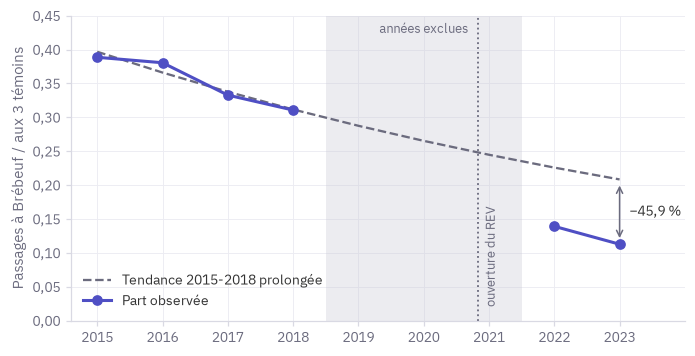

In [13]:
annees_tendance = np.arange(2015, 2024)
part_tendance = np.exp(origine + pente * annees_tendance)
ouverture_rev = 2020 + 10 / 12            # novembre 2020
attendue_2023 = part_brebeuf.loc[2023] / (1 + ecart_a_la_tendance[2023])


def tracer_part_brebeuf(couleurs):
    figure, axe = plt.subplots(figsize=(7.2, 3.6))
    axe.axvspan(2018.5, 2021.5, color=couleurs["neutre"], alpha=0.35, linewidth=0)
    axe.text(2020, 0.44, "années exclues", ha="center", va="top", fontsize=8.5, color=couleurs["secondaire"])
    axe.axvline(ouverture_rev, color=couleurs["trait"], linestyle=":", linewidth=1.2)
    axe.text(ouverture_rev + 0.1, 0.02, "ouverture du REV", rotation=90, va="bottom", fontsize=8.5,
             color=couleurs["secondaire"])
    axe.plot(annees_tendance, part_tendance, color=couleurs["trait"], linestyle="--", linewidth=1.5,
             label="Tendance 2015-2018 prolongée")
    for debut, fin in [(2015, 2018), (2022, 2023)]:
        axe.plot(part_brebeuf.loc[debut:fin], color=couleurs["accent"], marker="o", markersize=6, linewidth=2,
                 label="Part observée" if debut == 2015 else None)
    axe.annotate("", xy=(2023, part_brebeuf.loc[2023]), xytext=(2023, attendue_2023),
                 arrowprops={"arrowstyle": "<->", "color": couleurs["trait"], "linewidth": 1, "shrinkA": 4, "shrinkB": 4})
    axe.text(2023.15, (part_brebeuf.loc[2023] + attendue_2023) / 2, pourcentage(ecart_a_la_tendance[2023]).replace("-", "−"),
             va="center", fontsize=9, color=couleurs["texte"])
    axe.set_xticks(range(2015, 2024))
    axe.set_xlim(2014.6, 2024)
    axe.set_ylim(0, 0.45)
    axe.yaxis.set_major_formatter(en_francais(2))
    axe.set_ylabel("Passages à Brébeuf / aux 3 témoins")
    axe.legend(frameon=False, loc="lower left")
    return figure


sauver_clair_et_sombre(tracer_part_brebeuf, "resultats/part_brebeuf")